BFSK ORTHOGONALITY VALIDATION
--------------------------------
Inner product <c0,c1> = -1.3877787807814457e-17
Absolute inner product = 1.3877787807814457e-17
Result: The two cosine basis signals are orthogonal.

DETECTION RESULTS AT 8 dB
--------------------------------
ASK coherent: Errors = 0, BER = 0.0000
ASK noncoherent: Errors = 3, BER = 0.0300
BFSK coherent: Errors = 0, BER = 0.0000
BFSK noncoherent: Errors = 2, BER = 0.0200


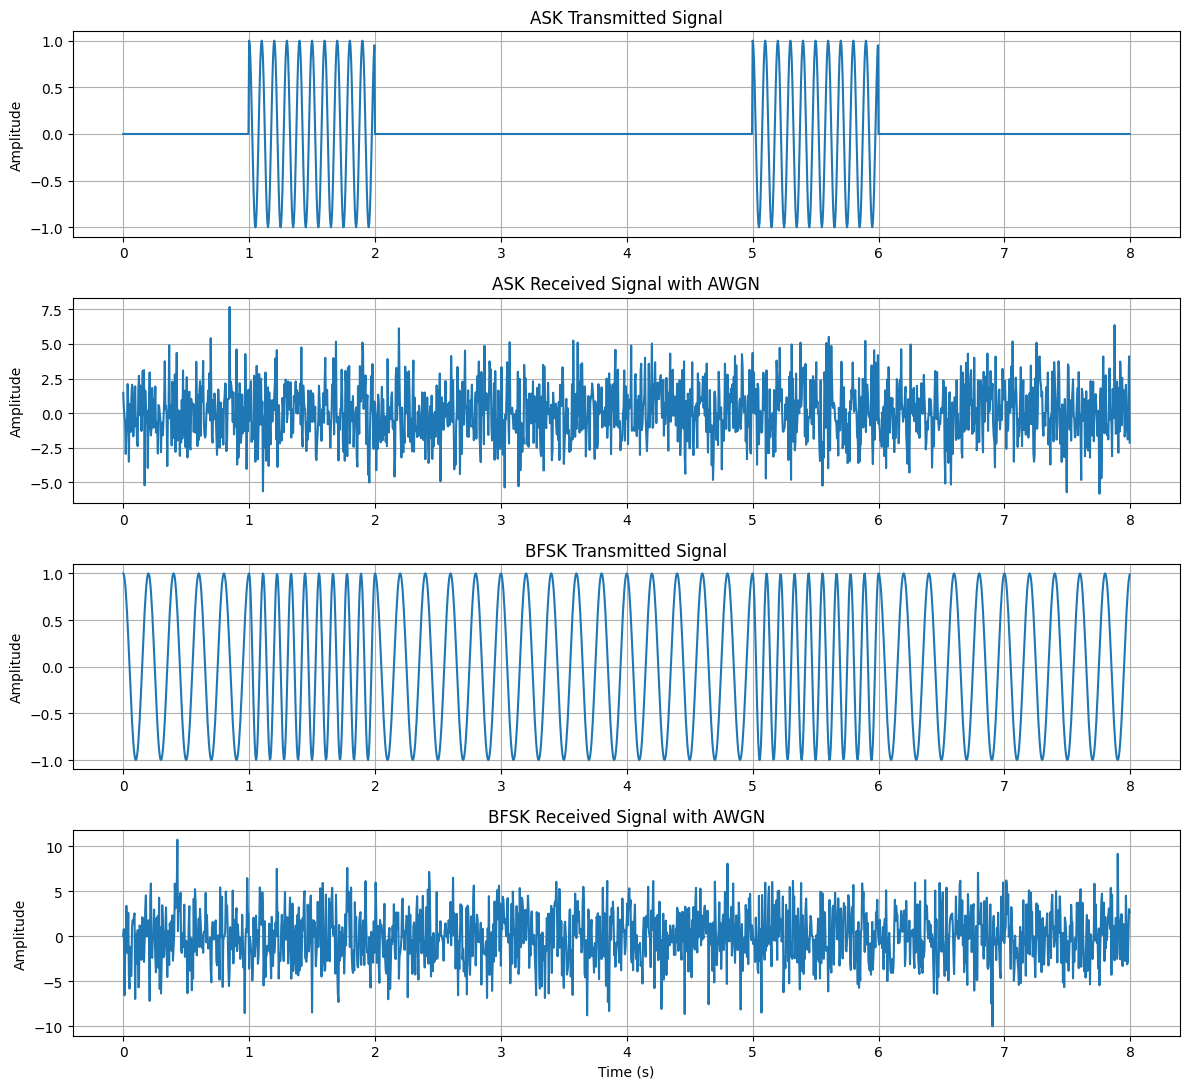

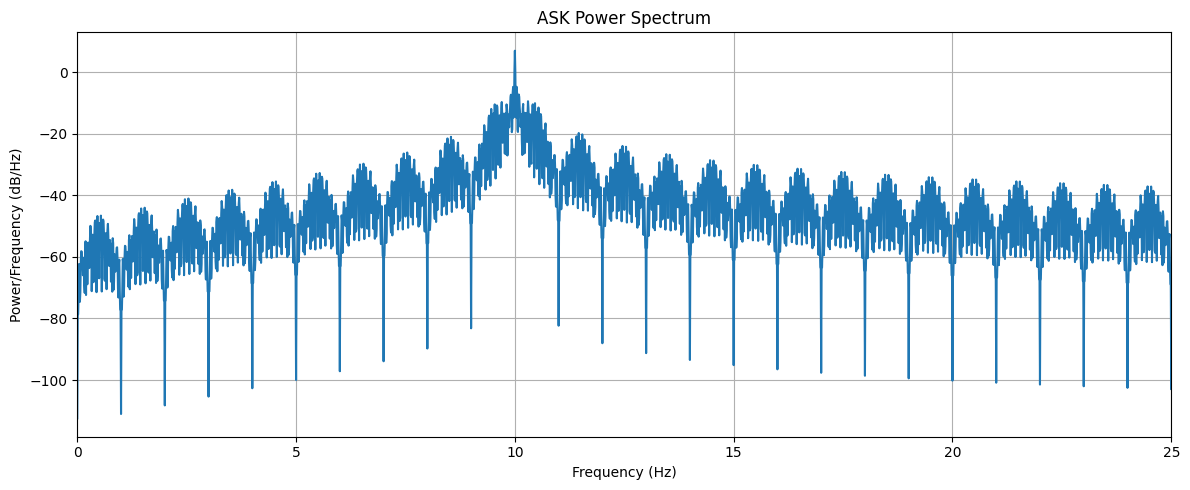

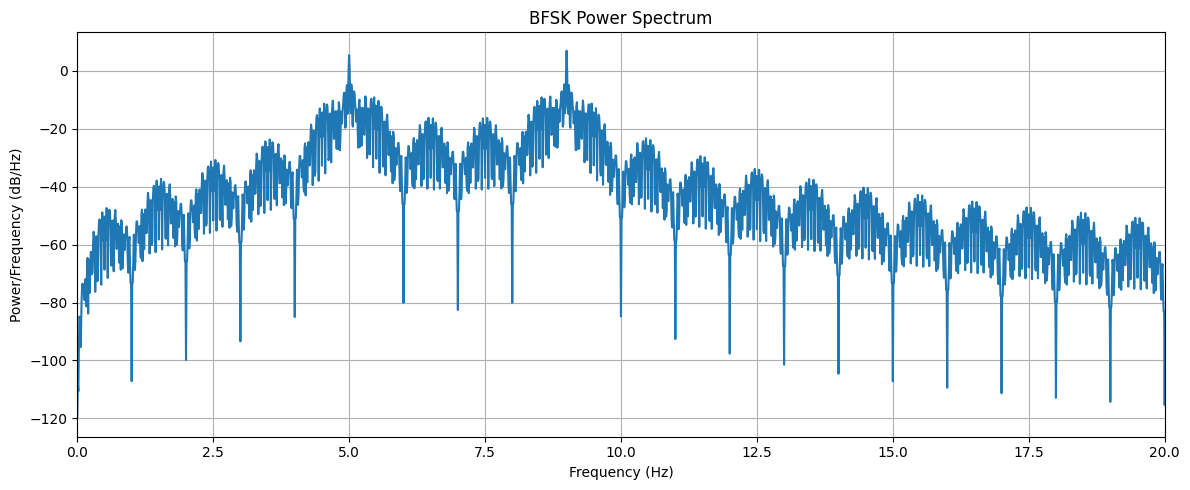

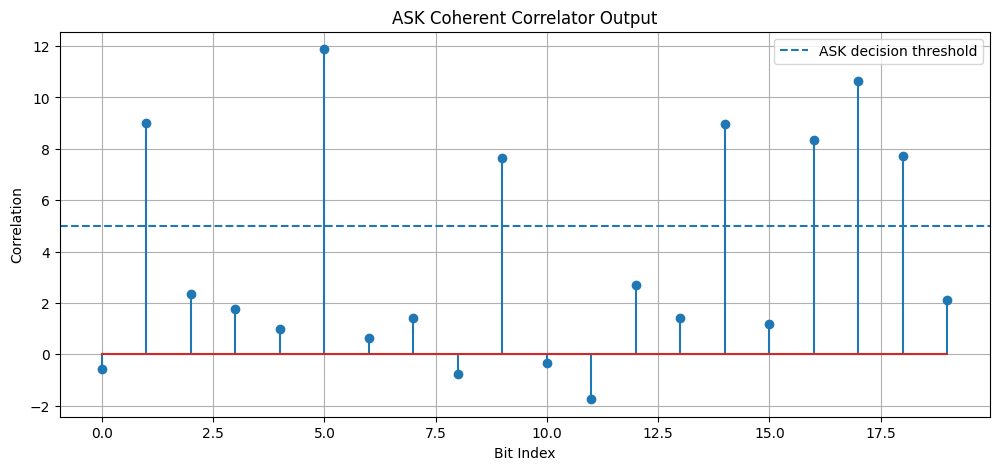

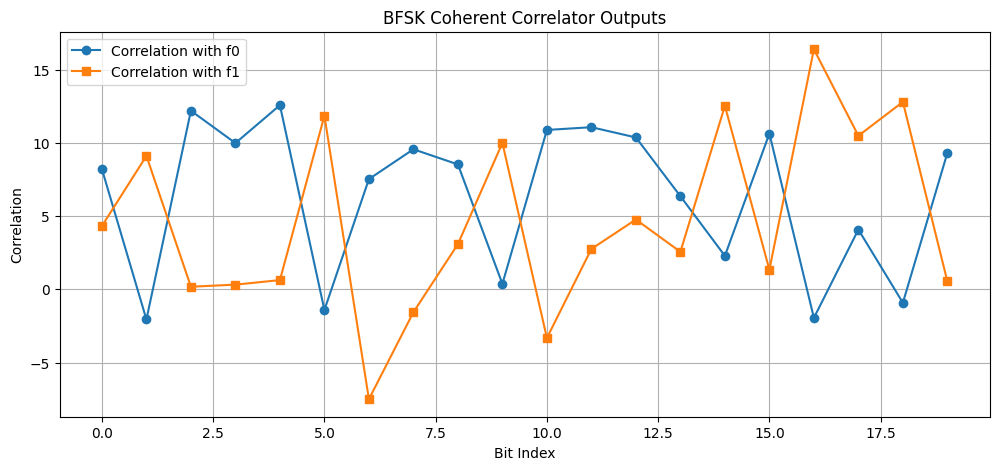

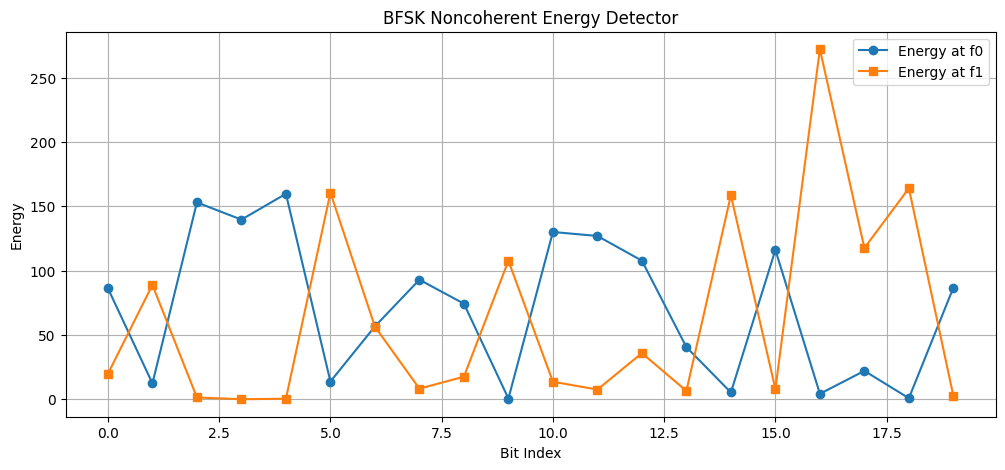

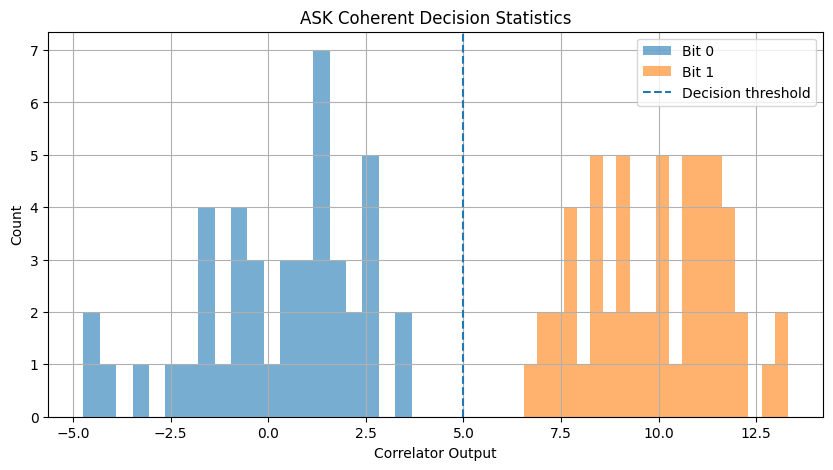

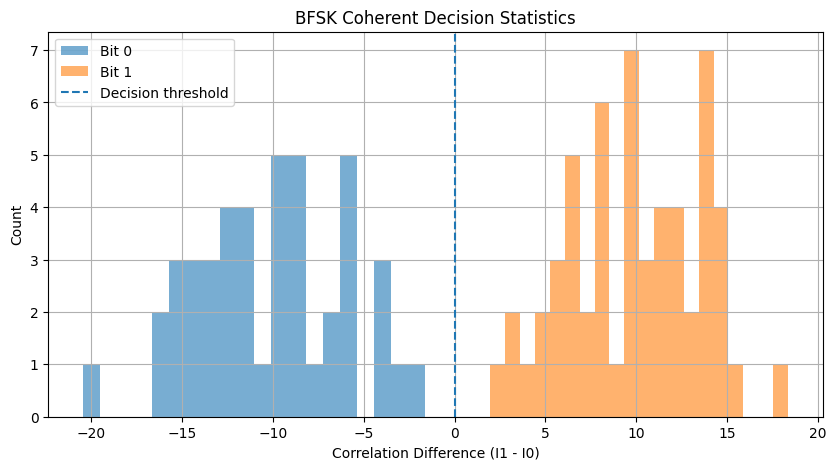

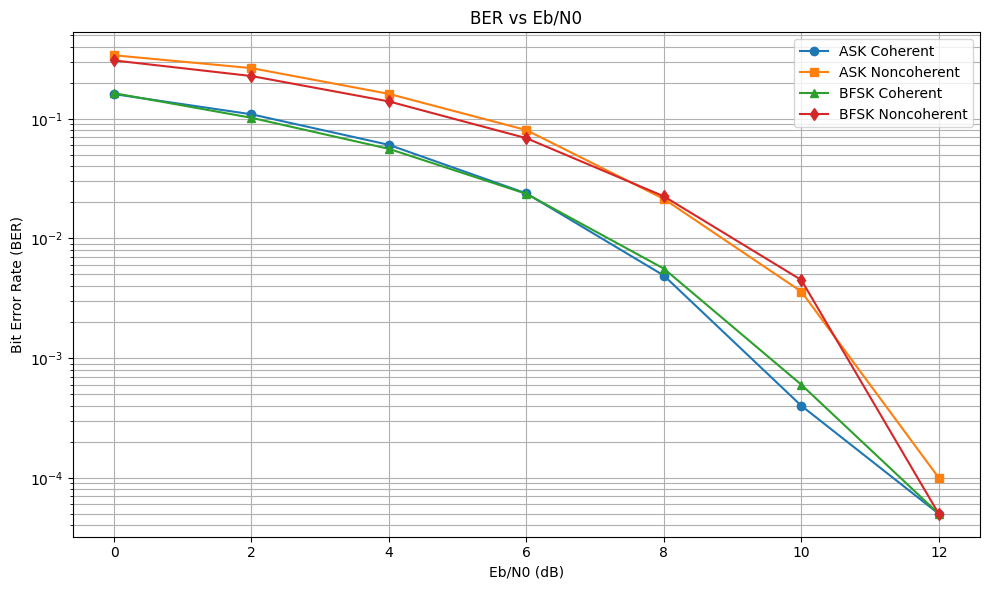

Spacing = 2, inner product = -1.752e-16, BER = 0.00450
Spacing = 4, inner product = -1.388e-17, BER = 0.00640
Spacing = 6, inner product = -3.469e-18, BER = 0.00620
Spacing = 8, inner product = -4.753e-16, BER = 0.00640


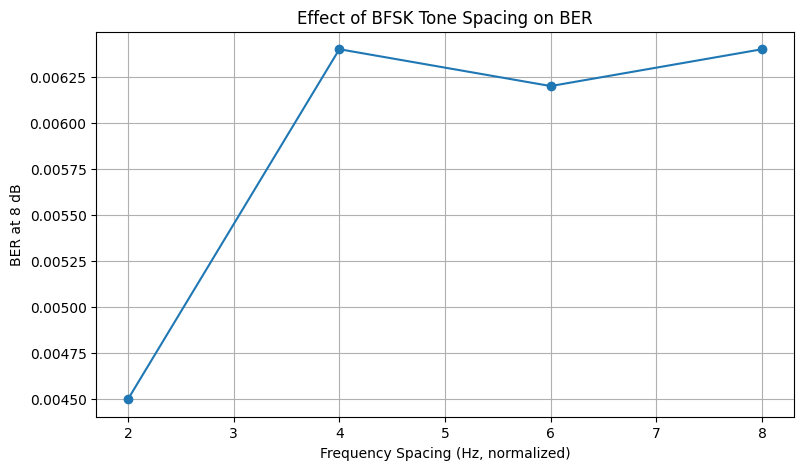


Experiment 9 simulation completed.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# EXPERIMENT 9: ASK AND BFSK
# Digital Communication Laboratory
# ============================================================

np.random.seed(42)

# -------------------- PARAMETERS ----------------------------
N = 200                  # Samples per bit
Tb = 1.0                 # Bit duration (normalized)
fs = N / Tb              # Sampling frequency
A = 1.0                  # Carrier amplitude
fc = 10.0                # ASK carrier frequency
f0 = 5.0                 # BFSK frequency for bit 0
f1 = 9.0                 # BFSK frequency for bit 1
num_bits = 100           # Bits for waveform visualization

t = np.arange(N) / fs
time_bit = np.arange(N) * Tb / N

# Normalized orthogonal reference signals
c_ask = np.sqrt(2/N) * np.cos(2*np.pi*fc*time_bit)
s_ask = np.sqrt(2/N) * np.sin(2*np.pi*fc*time_bit)

c0 = np.sqrt(2/N) * np.cos(2*np.pi*f0*time_bit)
s0 = np.sqrt(2/N) * np.sin(2*np.pi*f0*time_bit)
c1 = np.sqrt(2/N) * np.cos(2*np.pi*f1*time_bit)
s1 = np.sqrt(2/N) * np.sin(2*np.pi*f1*time_bit)

# ============================================================
# 1. MANDATORY VALIDATION: BFSK BASIS ORTHOGONALITY
# ============================================================

inner_product = np.dot(c0, c1)

print("BFSK ORTHOGONALITY VALIDATION")
print("--------------------------------")
print("Inner product <c0,c1> =", inner_product)
print("Absolute inner product =", abs(inner_product))

if abs(inner_product) < 1e-10:
    print("Result: The two cosine basis signals are orthogonal.")
else:
    print("Result: The signals are not perfectly orthogonal.")

# ============================================================
# 2. GENERATE RANDOM BINARY DATA
# ============================================================

bits = np.random.randint(0, 2, num_bits)

# ============================================================
# 3. ASK TRANSMITTER
# Bit 0 -> No carrier
# Bit 1 -> Carrier present
# ============================================================

ask_signal = (
    A * bits[:, None]
    * np.cos(2*np.pi*fc*time_bit)[None, :]
)

# ============================================================
# 4. BFSK TRANSMITTER
# Bit 0 -> Frequency f0
# Bit 1 -> Frequency f1
# ============================================================

bfsk_signal = np.where(
    bits[:, None] == 0,
    A * np.cos(2*np.pi*f0*time_bit)[None, :],
    A * np.cos(2*np.pi*f1*time_bit)[None, :]
)

# ============================================================
# 5. AWGN CHANNEL
# ============================================================

EbN0_dB = 8
gamma = 10**(EbN0_dB/10)

# Approximate average bit energies for the sampled signals
Eb_ask = A**2 * N / 4
Eb_fsk = A**2 * N / 2

sigma_ask = np.sqrt(Eb_ask / (2*gamma))
sigma_fsk = np.sqrt(Eb_fsk / (2*gamma))

ask_received = ask_signal + sigma_ask * np.random.randn(*ask_signal.shape)
fsk_received = bfsk_signal + sigma_fsk * np.random.randn(*bfsk_signal.shape)

# ============================================================
# 6. ASK COHERENT AND NONCOHERENT DETECTION
# ============================================================

# Coherent correlator
ask_I = ask_received @ c_ask
ask_coherent_bits = (ask_I > A*np.sqrt(N/2)/2).astype(int)

# Noncoherent quadrature/envelope detector
ask_Q = ask_received @ s_ask
ask_envelope = np.sqrt(ask_I**2 + ask_Q**2)
ask_noncoherent_bits = (
    ask_envelope > A*np.sqrt(N/2)/2
).astype(int)

# ============================================================
# 7. BFSK COHERENT AND NONCOHERENT DETECTION
# ============================================================

# Coherent correlator outputs
fsk_I0 = fsk_received @ c0
fsk_I1 = fsk_received @ c1

bfsk_coherent_bits = (fsk_I1 > fsk_I0).astype(int)

# Noncoherent energy detector using I/Q projections
fsk_Q0 = fsk_received @ s0
fsk_Q1 = fsk_received @ s1

energy0 = fsk_I0**2 + fsk_Q0**2
energy1 = fsk_I1**2 + fsk_Q1**2

bfsk_noncoherent_bits = (energy1 > energy0).astype(int)

# ============================================================
# 8. DISPLAY BIT ERRORS
# ============================================================

def report_errors(name, detected, original):
    errors = np.sum(detected != original)
    ber = errors / len(original)
    print(f"{name}: Errors = {errors}, BER = {ber:.4f}")

print("\nDETECTION RESULTS AT", EbN0_dB, "dB")
print("--------------------------------")
report_errors("ASK coherent", ask_coherent_bits, bits)
report_errors("ASK noncoherent", ask_noncoherent_bits, bits)
report_errors("BFSK coherent", bfsk_coherent_bits, bits)
report_errors("BFSK noncoherent", bfsk_noncoherent_bits, bits)

# ============================================================
# 9. PASSBAND WAVEFORMS
# ============================================================

show_bits = 8
t_total = np.arange(show_bits*N) / fs

ask_tx_plot = ask_signal[:show_bits].flatten()
fsk_tx_plot = bfsk_signal[:show_bits].flatten()
ask_rx_plot = ask_received[:show_bits].flatten()
fsk_rx_plot = fsk_received[:show_bits].flatten()

fig, ax = plt.subplots(4, 1, figsize=(12, 11))

ax[0].plot(t_total, ask_tx_plot)
ax[0].set_title("ASK Transmitted Signal")
ax[0].set_ylabel("Amplitude")
ax[0].grid(True)

ax[1].plot(t_total, ask_rx_plot)
ax[1].set_title("ASK Received Signal with AWGN")
ax[1].set_ylabel("Amplitude")
ax[1].grid(True)

ax[2].plot(t_total, fsk_tx_plot)
ax[2].set_title("BFSK Transmitted Signal")
ax[2].set_ylabel("Amplitude")
ax[2].grid(True)

ax[3].plot(t_total, fsk_rx_plot)
ax[3].set_title("BFSK Received Signal with AWGN")
ax[3].set_xlabel("Time (s)")
ax[3].set_ylabel("Amplitude")
ax[3].grid(True)

plt.tight_layout()
plt.show()

# ============================================================
# 10. POWER SPECTRAL DENSITY (PSD)
# ============================================================

def plot_psd(signal, title):
    x = signal.flatten()
    window = np.hanning(len(x))
    X = np.fft.rfft(x * window)
    freqs = np.fft.rfftfreq(len(x), d=1/fs)

    psd = (np.abs(X)**2) / (fs*np.sum(window**2) + 1e-15)

    plt.plot(freqs, 10*np.log10(psd + 1e-12))
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power/Frequency (dB/Hz)")
    plt.grid(True)

plt.figure(figsize=(12, 5))
plot_psd(ask_signal, "ASK Power Spectrum")
plt.xlim(0, 25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plot_psd(bfsk_signal, "BFSK Power Spectrum")
plt.xlim(0, 20)
plt.tight_layout()
plt.show()

# ============================================================
# 11. CORRELATOR OUTPUTS
# ============================================================

n_show = 20
idx = np.arange(n_show)

plt.figure(figsize=(12, 5))
plt.stem(idx, ask_I[:n_show])
plt.axhline(A*np.sqrt(N/2)/2, linestyle="--",
            label="ASK decision threshold")
plt.title("ASK Coherent Correlator Output")
plt.xlabel("Bit Index")
plt.ylabel("Correlation")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(idx, fsk_I0[:n_show], "o-", label="Correlation with f0")
plt.plot(idx, fsk_I1[:n_show], "s-", label="Correlation with f1")
plt.title("BFSK Coherent Correlator Outputs")
plt.xlabel("Bit Index")
plt.ylabel("Correlation")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(idx, energy0[:n_show], "o-", label="Energy at f0")
plt.plot(idx, energy1[:n_show], "s-", label="Energy at f1")
plt.title("BFSK Noncoherent Energy Detector")
plt.xlabel("Bit Index")
plt.ylabel("Energy")
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# 12. DECISION-STATISTIC HISTOGRAMS
# ============================================================

plt.figure(figsize=(10, 5))
plt.hist(ask_I[bits == 0], bins=20, alpha=0.6,
         label="Bit 0")
plt.hist(ask_I[bits == 1], bins=20, alpha=0.6,
         label="Bit 1")
plt.axvline(A*np.sqrt(N/2)/2, linestyle="--",
            label="Decision threshold")
plt.title("ASK Coherent Decision Statistics")
plt.xlabel("Correlator Output")
plt.ylabel("Count")
plt.legend()
plt.grid(True)
plt.show()

fsk_difference = fsk_I1 - fsk_I0

plt.figure(figsize=(10, 5))
plt.hist(fsk_difference[bits == 0], bins=20, alpha=0.6,
         label="Bit 0")
plt.hist(fsk_difference[bits == 1], bins=20, alpha=0.6,
         label="Bit 1")
plt.axvline(0, linestyle="--", label="Decision threshold")
plt.title("BFSK Coherent Decision Statistics")
plt.xlabel("Correlation Difference (I1 - I0)")
plt.ylabel("Count")
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# 13. BER CURVES FOR COHERENT AND NONCOHERENT DETECTION
# ============================================================

snr_db = np.arange(0, 13, 2)
num_test_bits = 10000

ber_ask_coh = []
ber_ask_non = []
ber_fsk_coh = []
ber_fsk_non = []

cos_fc = np.cos(2*np.pi*fc*time_bit)
cos_f0 = np.cos(2*np.pi*f0*time_bit)
cos_f1 = np.cos(2*np.pi*f1*time_bit)

for snr in snr_db:
    gamma = 10**(snr/10)

    test_bits = np.random.randint(0, 2, num_test_bits)

    # ---------- ASK ----------
    ask_clean = A * test_bits[:, None] * cos_fc[None, :]
    noise_std_ask = np.sqrt(Eb_ask/(2*gamma))
    ask_noisy = ask_clean + noise_std_ask * np.random.randn(
        num_test_bits, N
    )

    I_ask = ask_noisy @ c_ask
    Q_ask = ask_noisy @ s_ask

    det_ask_coh = (I_ask > A*np.sqrt(N/2)/2).astype(int)
    det_ask_non = (
        np.sqrt(I_ask**2 + Q_ask**2) >
        A*np.sqrt(N/2)/2
    ).astype(int)

    ber_ask_coh.append(np.mean(det_ask_coh != test_bits))
    ber_ask_non.append(np.mean(det_ask_non != test_bits))

    # ---------- BFSK ----------
    fsk_clean = np.where(
        test_bits[:, None] == 0,
        A*cos_f0[None, :],
        A*cos_f1[None, :]
    )

    noise_std_fsk = np.sqrt(Eb_fsk/(2*gamma))
    fsk_noisy = fsk_clean + noise_std_fsk * np.random.randn(
        num_test_bits, N
    )

    I0 = fsk_noisy @ c0
    I1 = fsk_noisy @ c1
    Q0 = fsk_noisy @ s0
    Q1 = fsk_noisy @ s1

    det_fsk_coh = (I1 > I0).astype(int)
    det_fsk_non = (
        I1**2 + Q1**2 > I0**2 + Q0**2
    ).astype(int)

    ber_fsk_coh.append(np.mean(det_fsk_coh != test_bits))
    ber_fsk_non.append(np.mean(det_fsk_non != test_bits))

# Avoid zero BER on a log-scale graph
ber_ask_coh = np.maximum(ber_ask_coh, 0.5/num_test_bits)
ber_ask_non = np.maximum(ber_ask_non, 0.5/num_test_bits)
ber_fsk_coh = np.maximum(ber_fsk_coh, 0.5/num_test_bits)
ber_fsk_non = np.maximum(ber_fsk_non, 0.5/num_test_bits)

plt.figure(figsize=(10, 6))
plt.semilogy(snr_db, ber_ask_coh, "o-", label="ASK Coherent")
plt.semilogy(snr_db, ber_ask_non, "s-", label="ASK Noncoherent")
plt.semilogy(snr_db, ber_fsk_coh, "^-", label="BFSK Coherent")
plt.semilogy(snr_db, ber_fsk_non, "d-", label="BFSK Noncoherent")
plt.title("BER vs Eb/N0")
plt.xlabel("Eb/N0 (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 14. EFFECT OF BFSK TONE SPACING
# ============================================================

spacing_values = [2, 4, 6, 8]
spacing_ber = []

for spacing in spacing_values:
    tone0 = 5
    tone1 = tone0 + spacing

    ref0 = np.sqrt(2/N) * np.cos(2*np.pi*tone0*time_bit)
    ref1 = np.sqrt(2/N) * np.cos(2*np.pi*tone1*time_bit)

    # Check orthogonality of the selected cosine references
    ip = np.dot(ref0, ref1)

    # Use a common, fixed Eb/N0 for comparison
    snr = 8
    gamma = 10**(snr/10)
    noise_std = np.sqrt(Eb_fsk/(2*gamma))

    test_bits = np.random.randint(0, 2, num_test_bits)
    tx = np.where(
        test_bits[:, None] == 0,
        A*np.cos(2*np.pi*tone0*time_bit)[None, :],
        A*np.cos(2*np.pi*tone1*time_bit)[None, :]
    )

    rx = tx + noise_std * np.random.randn(num_test_bits, N)

    # Coherent correlation detector
    corr0 = rx @ ref0
    corr1 = rx @ ref1
    detected = (corr1 > corr0).astype(int)

    spacing_ber.append(np.mean(detected != test_bits))

    print(
        f"Spacing = {spacing}, inner product = {ip:.3e}, "
        f"BER = {spacing_ber[-1]:.5f}"
    )

plt.figure(figsize=(9, 5))
plt.plot(spacing_values, spacing_ber, "o-")
plt.title("Effect of BFSK Tone Spacing on BER")
plt.xlabel("Frequency Spacing (Hz, normalized)")
plt.ylabel("BER at 8 dB")
plt.grid(True)
plt.show()

print("\nExperiment 9 simulation completed.")